# Bell.DiffAlgebra и Bell.Integrators против COSY INFINITY 10.2: точность и скорость
Бенчмарк чистой математики DA и интегрирования ОДУ с DA-начальными условиями. Все данные — в `output/*.csv`,
COSY-часть — `cosy/*.fox` (запуск `cosy/run_cosy_da.ps1`, `cosy/run_cosy_ode.ps1`), Julia-часть — `julia/*.jl`
(окружение `julia/Project.toml`, Bell подключён через `Pkg.develop`). Ядро BELL не менялось; все ускорения — прототипы в `julia/da_fast.jl`, `julia/rk_fast.jl`.

**Методика времени.** COSY: `CPUSEC` (разрешение 1/64 с), каждая операция повторяется с удвоением числа повторов до ≥ 2 с (ОДУ: ≥ 1 с);
вычтены накладные расходы цикла FOX (операция `assign`). Julia: `BenchmarkTools` (медиана для DA-операций, минимум для прочего), после прогрева;
время компиляции — отдельно. Один поток, одна машина, последовательные запуски.

In [1]:
import pandas as pd, numpy as np, matplotlib.pyplot as plt
pd.set_option('display.width', 200); pd.set_option('display.max_columns', 30)
acc = pd.read_csv('output/da_accuracy.csv'); tim = pd.read_csv('output/da_timing.csv'); comp = pd.read_csv('output/da_compile.csv')
fast = pd.read_csv('output/da_fast.csv'); wp = pd.read_csv('output/ode_workprecision.csv'); oc = pd.read_csv('output/ode_cosy.csv')
same = pd.read_csv('output/hh_rk4_same.csv'); prof = pd.read_csv('output/profile.csv'); rkf = pd.read_csv('output/rk_fast.csv')

## 1. Задачи для DA
$v = x_1 + 0.5x_2 - 0.3x_3 + 0.2x_4 + 0.1x_5 - 0.4x_6$, число переменных $n_v=6$, порядки $N = 3, 5, 7, 10$
(84, 462, 1716, 8008 мономов). Функции: $\sqrt{1+v}$, $e^v$, $\sin(0.3+v)$, $1/(1+x_1+x_2)$, $\ln(2+v)$, $\arctan(0.2+v)$,
$\cosh v\,\tan(0.1+v)$, $\sqrt{1+v}(1+v)^2$, произведение $e^v\sin(0.3+v)$, композиции $e^v\circ M$, $\sin(0.3+v)\circ M$ и обращение
отображения $M^{-1}$, где $M_i = x_i + 0.5x_{i+1} + 0.2x_ix_{i+3} + 0.1\sin(v)\,x_{i+1}^2$ (индексы циклически). Определения в
`cosy/da_ops_template.fox` и `julia/da_compare.jl` идентичны. COSY пишет DA через `WRITE`, Julia разбирает (`julia/cosy_io.jl`).

## 2. Совпадение коэффициентов
`max_rel_diff` = $\max_\alpha |c^{Bell}_\alpha - c^{COSY}_\alpha| / \max_\alpha |c_\alpha|$ (по всем мономам, включая не напечатанные COSY).
`max_rel_per_coef` — худшее относительное отличие отдельного коэффициента (велико только у коэффициентов, близких к нулю из-за сокращений).

In [2]:
acc.pivot_table(index='name', columns='order', values='max_rel_diff', sort=False).style.format('{:.1e}')

order,3,5,7,10
name,,,,
sqrt(1+v),6.9e-18,1.4e-17,5.6e-17,1.1e-16
exp(v),5.6e-17,5.6e-17,5.6e-17,5.6e-17
sin(0.3+v),1.7e-16,1.7e-16,1.7e-16,1.7e-16
1/(1+x1+x2),0.0e+00,0.0e+00,0.0e+00,0.0e+00
log(2+v),1.0e-17,1.0e-17,1.0e-17,1.0e-17
atan(0.2+v),8.7e-17,2.3e-16,4.5e-16,2.1e-15
cosh(v)tan(0.1+v),3.5e-16,7.7e-16,1.1e-15,2.7e-15
sqrt(1+v)(1+v)^2,8.9e-17,8.9e-17,8.9e-17,1.8e-16
exp(v)sin(0.3+v),3.5e-16,3.5e-16,3.5e-16,3.5e-16


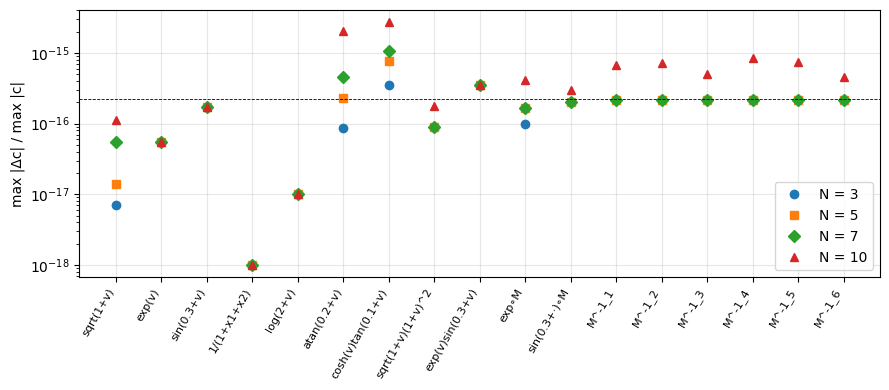

In [3]:
fig, ax = plt.subplots(figsize=(9, 4))
for o, m in zip([3, 5, 7, 10], 'osD^'):
    a = acc[acc.order == o]; ax.semilogy(range(len(a)), a.max_rel_diff.clip(lower=1e-18), m, label=f'N = {o}')
ax.axhline(2.2e-16, color='k', lw=.6, ls='--'); ax.set_xticks(range(len(a))); ax.set_xticklabels(a.name, rotation=60, ha='right', fontsize=8)
ax.set_ylabel('max |Δc| / max |c|'); ax.legend(); ax.grid(alpha=.3); plt.tight_layout(); plt.savefig('fig_da_accuracy.png', dpi=110); plt.show()

**Рисунок 1.** Нормированное максимальное расхождение коэффициентов Bell.DiffAlgebra и COSY для каждой задачи и порядка
(значения 0 показаны на уровне $10^{-18}$; пунктир — машинное $\varepsilon$). Все задачи совпадают на уровне $10^{-17}$–$3\cdot10^{-15}$,
т.е. до округления; рост с порядком отражает только накопление ошибок округления в длинных рядах (порядок 10, $\arctan$, $\tan$).
Число ненулевых коэффициентов одинаково (COSY не печатает коэффициенты, точно равные 0: в $e^v$ при $N=10$ один моном $< \varepsilon$).

## 3. Скорость DA-операций
Аргументы плотные: $A=\sin(0.3+v)$, $B=e^v$ (все мономы ненулевые). `compose6` — композиция 6 функций $M\circ M$, `invmap6` — $M^{-1}$.

In [4]:
t = tim.copy(); t['ratio'] = t.bell_s / t.cosy_s
t.pivot_table(index='op', columns='order', values='ratio', sort=False).style.format('{:.2f}').set_caption('Время Bell / время COSY (<1: Bell быстрее)')

order,3,5,7,10
op,,,,
mul,0.55,0.50,0.64,0.51
add,0.36,0.27,0.18,0.20
exp,1.02,0.67,0.64,0.67
sin,1.00,0.67,0.63,0.66
sqrt,0.63,0.62,0.63,0.66
inv,0.84,0.62,0.62,0.67
compose6,2.04,4.23,4.61,8.92
invmap6,0.96,2.80,3.84,6.77


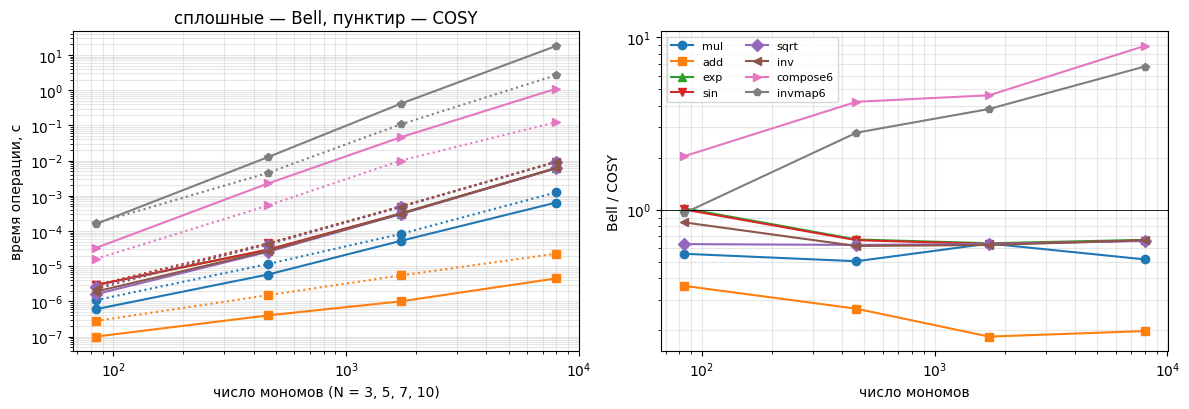

In [5]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4.2))
for op, m in zip(['mul', 'add', 'exp', 'sin', 'sqrt', 'inv', 'compose6', 'invmap6'], 'os^vD<>p'):
    a = tim[tim.op == op]
    ax[0].loglog(a.nmonomials, a.bell_s, m + '-', label=op); ax[0].loglog(a.nmonomials, a.cosy_s, m + ':', color=ax[0].lines[-1].get_color())
    ax[1].semilogx(a.nmonomials, a.bell_s / a.cosy_s, m + '-', label=op)
ax[0].set_xlabel('число мономов (N = 3, 5, 7, 10)'); ax[0].set_ylabel('время операции, с'); ax[0].set_title('сплошные — Bell, пунктир — COSY')
ax[1].axhline(1, color='k', lw=.6); ax[1].set_xlabel('число мономов'); ax[1].set_ylabel('Bell / COSY'); ax[1].set_yscale('log')
for a_ in ax: a_.grid(alpha=.3, which='both')
ax[1].legend(fontsize=8, ncol=2); plt.tight_layout(); plt.savefig('fig_da_speed.png', dpi=110); plt.show()

**Рисунок 2.** Слева: абсолютное время одной операции в Bell (сплошные линии) и COSY (пунктир) в зависимости от размера DA.
Справа: отношение Bell/COSY. Умножение в Bell в ~2 раза быстрее COSY, сложение в 3–5 раз быстрее, элементарные функции
(ряд Тейлора + схема Горнера) в ~1.5 раза быстрее при $N\ge5$ и наравне при $N=3$. Композиция и обращение отображения в Bell
медленнее COSY в 2–9 раз, и разрыв растёт с порядком — это главная найденная слабость (см. раздел 6).

In [6]:
comp

,item,seconds
0,using Bell (load),1.039000
1,first problems(3) call incl. compilation,0.242451
2,second call,0.000881


**Компиляция.** Загрузка `using Bell` и первая (компилирующая) серия всех DA-задач порядка 3 — разовая стоимость JIT на процесс (секунды);
повторный вызов той же серии — миллисекунды. Во всех таблицах время измерено после прогрева.

## 4. ОДУ с DA-начальными условиями
* **hh** — Хенона–Хейлеса, $n_v=4$, $z_0=(0.1,-0.2,0.25,0.1)+\text{DA}$, $T=1$. COSY: RK4 с фиксированным шагом, написанный на FOX
  (тот же алгоритм, что `Bell.Integrators.RK4`) — прямое сравнение стоимости одинаковой DA-арифметики.
* **quad** — квадруполь `MQ 0.5 0.5 0.05` (протон 200 МэВ), точный гамильтониан $H=-\sqrt{(1+\delta)^2-a^2-b^2}+\tfrac{k}{2}(x^2-y^2)$.
* **dipole** — секторный однородный диполь `MS 2 30 0.05`, $H=-(1+hx)\sqrt{(1+\delta)^2-a^2-b^2}+hx+\tfrac{h^2x^2}{2}$.

Для элементов $n_v=6$ (переменные COSY $x,a,y,b,l,\delta_K$); в Bell $1+\delta = \sqrt{(1+\delta_K)((1+\delta_K)\eta+2)/(\eta+2)}$ как DA от $\delta_K$,
$\eta = K/mc^2$ и $B\rho$ берутся из COSY (`refpart.txt`). Сравниваются строки $x,a,y,b$ отображения.

**Что на самом деле делает COSY для элементов.** При порядке ≥ 3 `MQ`/`MS` без краевых полей идут через `FFELE → SIELE`, где отображение
s-независимого элемента вычисляется не Рунге–Куттой, а **DA-оператором потока** (`DAFLO`): ряд $\exp(L\,F\cdot\nabla)\,\mathrm{id}$. RK8 COSY
(`PROCEDURE RK`) используется только для s-зависимых полей (краевые поля FR 1/3). Поэтому в Bell добавлен собственный прототип того же класса —
`daflow` в `julia/da_fast.jl` (ряд Ли по $L$, общая теория DA, Berz «Modern Map Methods»).

Ошибка = $\max_i\|z_i - z_i^{ref}\| / \max_i\|z_i^{ref}\|$ по коэффициентам. Эталон: hh — GBS(8), tol $10^{-14}$; элементы — DA-поток (совпадает с COSY до $10^{-16}$).

In [7]:
oc[~oc.what.str.startswith('COSY FOX')].pivot_table(index=['problem', 'what'], columns='order', values=['time_s', 'err_vs_ref']).style.format('{:.2e}')

**Совпадение с COSY.** Отображения квадруполя и диполя Bell (DA-поток, DOP853 tol $10^{-15}$) и COSY совпадают до $4\cdot10^{-16}$–$3\cdot10^{-15}$
относительно на всех порядках 3–10, т.е. соглашения о координатах и физика (точный корень) идентичны. Время одной карты: прототип DA-потока Bell
равен COSY с точностью до множителя ~1 (0.6–0.8 для диполя — Bell быстрее, 1.1–2.9 для квадруполя).

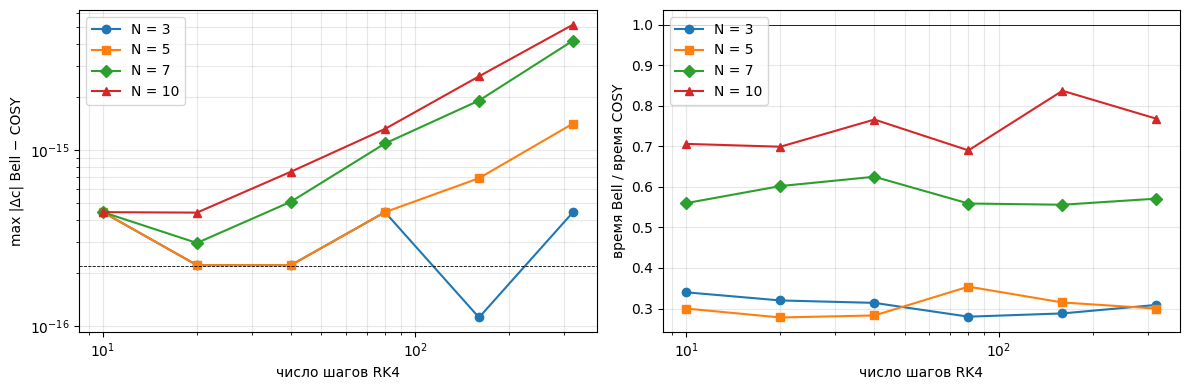

In [8]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for o, m in zip([3, 5, 7, 10], 'osD^'):
    a = same[same.order == o]; ax[0].semilogy(a.nsteps, a.max_abs_diff.clip(lower=1e-17), m + '-', label=f'N = {o}')
    ax[1].semilogx(a.nsteps, a.ratio, m + '-', label=f'N = {o}')
ax[0].set_xscale('log'); ax[0].set_xlabel('число шагов RK4'); ax[0].set_ylabel('max |Δc| Bell − COSY'); ax[0].axhline(2.2e-16, color='k', lw=.6, ls='--')
ax[1].axhline(1, color='k', lw=.6); ax[1].set_xlabel('число шагов RK4'); ax[1].set_ylabel('время Bell / время COSY')
for a_ in ax: a_.grid(alpha=.3, which='both'); a_.legend()
plt.tight_layout(); plt.savefig('fig_hh_rk4_same.png', dpi=110); plt.show()

**Рисунок 3.** Один и тот же алгоритм (RK4, фиксированный шаг, Хенона–Хейлеса, $n_v=4$) в Bell и в COSY (FOX).
Слева: коэффициенты совпадают до $10^{-16}$–$5\cdot10^{-15}$ (рост ~ число шагов × ε). Справа: Bell в 3 раза быстрее при $N\le5$ и в 1.2–1.8 раза при $N=7$–$10$
(при малых порядках у COSY велика доля интерпретатора FOX).

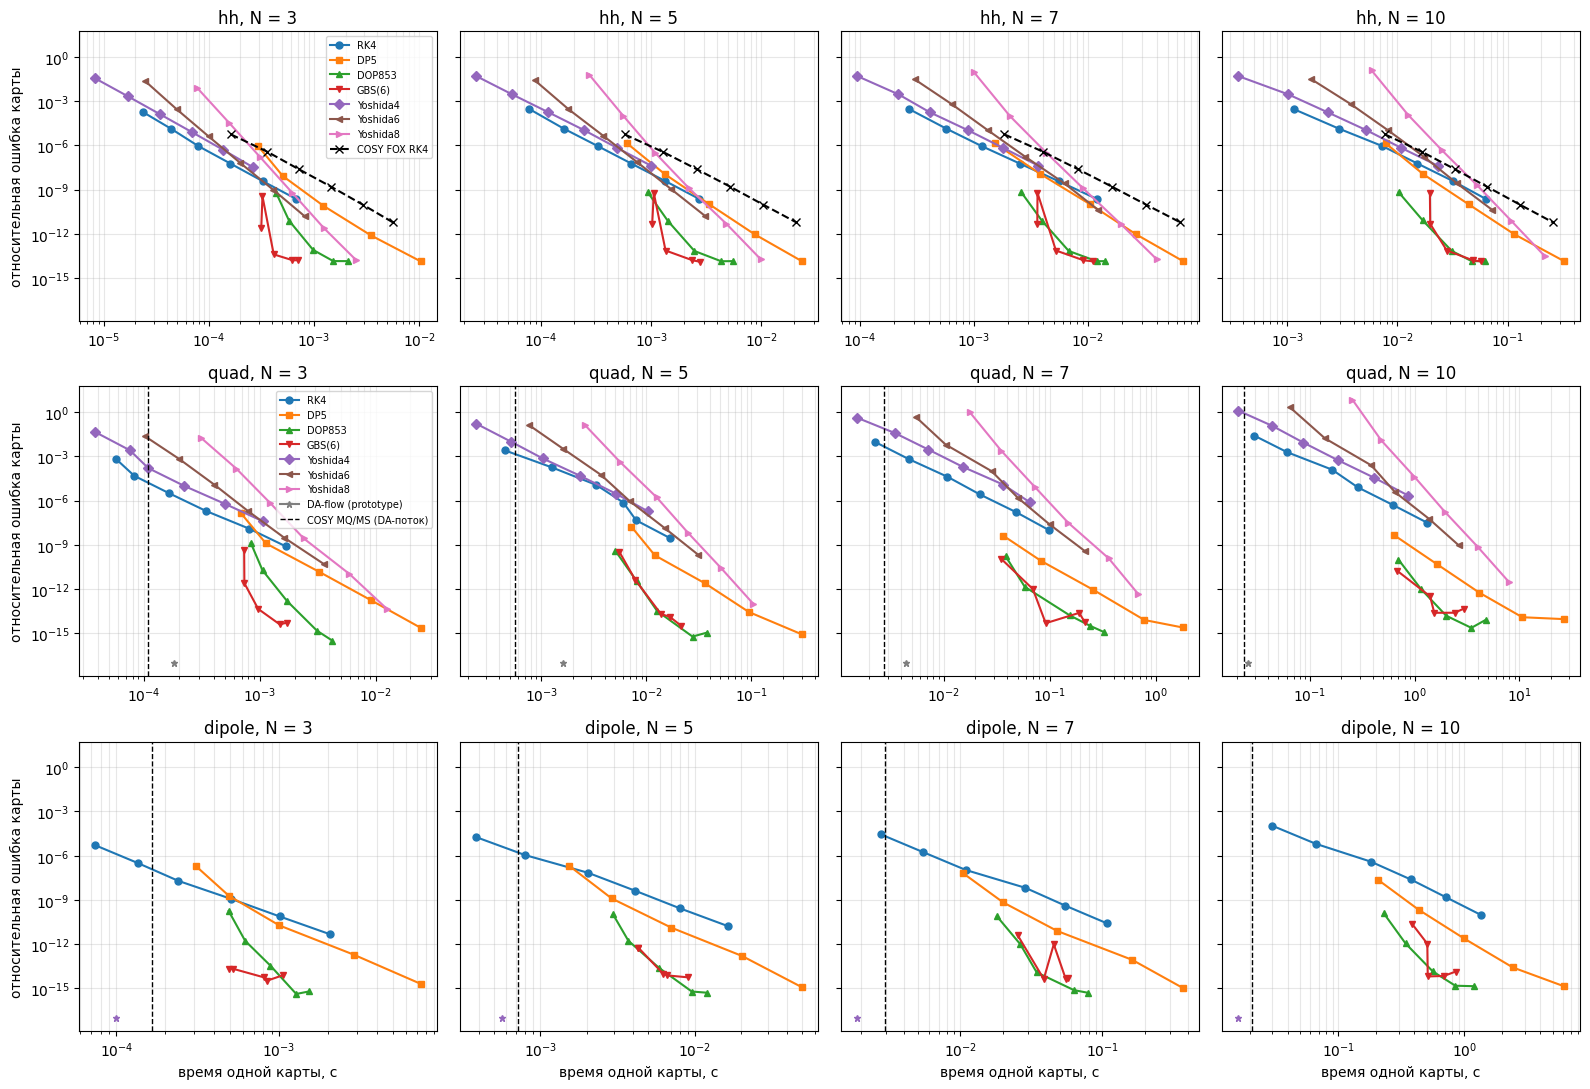

In [9]:
methods = ['RK4', 'DP5', 'DOP853', 'GBS(6)', 'Yoshida4', 'Yoshida6', 'Yoshida8', 'DA-flow (prototype)']
mk = dict(zip(methods, 'os^vD<>*'))
fig, axs = plt.subplots(3, 4, figsize=(16, 11), sharey=True)
for r_, pr in enumerate(['hh', 'quad', 'dipole']):
    for c_, o in enumerate([3, 5, 7, 10]):
        ax = axs[r_, c_]; d = wp[(wp.problem == pr) & (wp.order == o)]
        for mth in methods:
            a = d[d.method == mth].sort_values('time_s')
            if len(a): ax.loglog(a.time_s, a.err_vs_ref.clip(lower=1e-17), mk[mth] + '-', ms=5, label=mth)
        cs = oc[(oc.problem == pr) & (oc.order == o) & oc.what.str.startswith('COSY')]
        if pr == 'hh': ax.loglog(cs.time_s, cs.err_vs_ref, 'kx--', label='COSY FOX RK4')
        else: ax.axvline(cs.time_s.iloc[0], color='k', ls='--', lw=1, label='COSY MQ/MS (DA-поток)')
        ax.set_title(f'{pr}, N = {o}'); ax.grid(alpha=.3, which='both')
        if c_ == 0: ax.set_ylabel('относительная ошибка карты')
        if r_ == 2: ax.set_xlabel('время одной карты, с')
axs[0, 0].legend(fontsize=7); axs[1, 0].legend(fontsize=7)
plt.tight_layout(); plt.savefig('fig_workprecision.png', dpi=100); plt.show()

**Рисунок 4.** Диаграммы «работа–точность»: время вычисления одной DA-карты против её относительной ошибки, для каждого метода Bell
(точки — разные шаги/допуски), строки — задачи, столбцы — порядки DA. Чёрный пунктир: hh — тот же RK4 в COSY (5 вариантов числа шагов);
элементы — время карты COSY (вертикаль, точность $\sim10^{-16}$). Точки на нижней границе — ошибка ниже $10^{-17}$ (DA-поток = эталон).
Выводы: (i) для s-независимых элементов DA-поток (COSY и прототип Bell) быстрее любого RK в 5–55 раз (при =10$ — в 30–55 раз) при машинной точности;
(ii) среди интеграторов при точности $10^{-12}$ лидируют GBS(6) и DOP853, DP5 в 2–4 раза дороже, RK4 и Yoshida4 не достигают $10^{-12}$ за 128/64 шагов;
(iii) Yoshida 6/8 обходятся дороже DOP853/GBS при равной точности — их ценность в симплектичности, а не в эффективности на коротких отрезках.

In [10]:
rows = []
for tgt in (1e-8, 1e-12):
    r = wp[wp.err_vs_ref <= tgt].groupby(['problem', 'order', 'method']).time_s.min().reset_index(); r['target'] = tgt; rows.append(r)
rank = pd.concat(rows); rank.to_csv('output/integrator_ranking.csv', index=False)
rank.pivot_table(index=['target', 'problem', 'order'], columns='method', values='time_s').style.format('{:.2e}', na_rep='—').set_caption('Минимальное время карты (с) для достижения ошибки ≤ target; — = не достигнуто в сетке параметров')

In [11]:
best = rank[rank.method != 'DA-flow (prototype)'].sort_values('time_s').groupby(['target', 'problem', 'order']).head(1)
best.pivot_table(index=['problem', 'order'], columns='target', values='method', aggfunc='first')

target        1.000000e-12 1.000000e-08
problem order                          
dipole  3           GBS(6)       DOP853
        5           GBS(6)          DP5
        7           DOP853       DOP853
        10          GBS(6)       DOP853
hh      3           GBS(6)       GBS(6)
        5           GBS(6)       DOP853
        7           GBS(6)       DOP853
        10          GBS(6)       DOP853
quad    3           GBS(6)       GBS(6)
        5           DOP853       DOP853
        7           GBS(6)       GBS(6)
        10          GBS(6)          DP5

**Таблица.** Лучший RK/симплектический метод (без DA-потока) по задаче, порядку и целевой точности. Шаговое управление для DA-состояний
идёт по норме всех коэффициентов; высокие порядки задают шаг, поэтому адаптивным методам при $N=10$ требуется в 2–3 раза больше шагов, чем при $N=3$.

## 5. Где Bell тратит время (профилирование)
Квадруполь, DOP853, tol $10^{-12}$, $n_v=6$. RHS измерен на плотном состоянии (на почти единичном состоянии DA разреженные и умножение в разы дешевле —
такая ошибка измерения легко даёт неверный вывод). Модель RHS = 4 mul + sqrt + inv + 4 axpy; `t_*` — время отдельных операций на тех же данных.

In [12]:
prof

,order,total_s,gc_frac,bytes_per_rhs,nfev,t_rhs_s,t_mul_s,t_sqrt_s,t_inv_s,t_axpy_s,rhs_model_s,frac_rhs_in_total,frac_lincomb_in_total
0,5,0.029161,0.209,168276,299,0.000017,0.000001,0.000006,0.000006,2.205400e-07,0.000017,0.178,0.822
1,7,0.172530,0.318,776616,429,0.000115,0.000006,0.000038,0.000038,6.708000e-07,0.000104,0.285,0.715
2,10,2.120400,0.308,4748438,624,0.001395,0.000057,0.000485,0.000475,3.416700e-06,0.001200,0.410,0.590


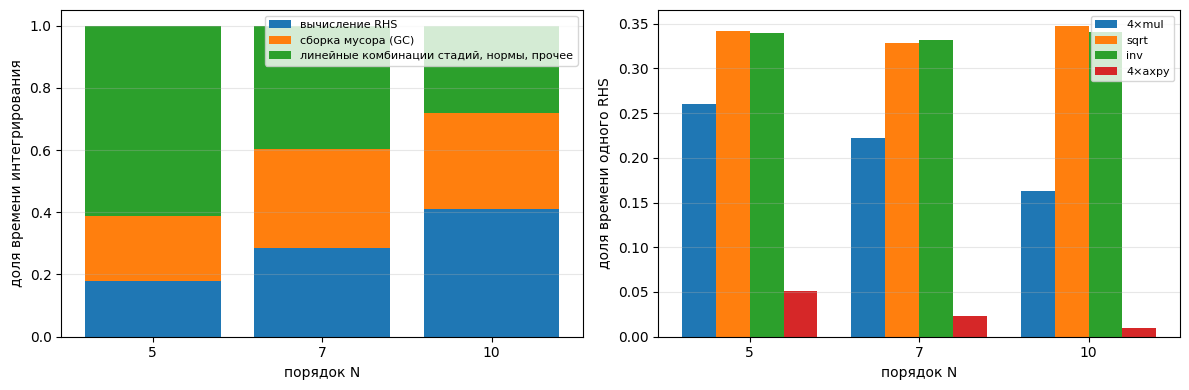

In [13]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
o = prof.order.astype(str)
ax[0].bar(o, prof.frac_rhs_in_total, label='вычисление RHS'); ax[0].bar(o, prof.gc_frac, bottom=prof.frac_rhs_in_total, label='сборка мусора (GC)')
ax[0].bar(o, 1 - prof.frac_rhs_in_total - prof.gc_frac, bottom=prof.frac_rhs_in_total + prof.gc_frac, label='линейные комбинации стадий, нормы, прочее')
ax[0].set_xlabel('порядок N'); ax[0].set_ylabel('доля времени интегрирования'); ax[0].legend(fontsize=8)
w = 0.2; x = np.arange(len(prof))
for k, (c, l) in enumerate([('t_mul_s', '4×mul'), ('t_sqrt_s', 'sqrt'), ('t_inv_s', 'inv'), ('t_axpy_s', '4×axpy')]):
    v = prof[c] * (4 if c in ('t_mul_s', 't_axpy_s') else 1) / prof.t_rhs_s; ax[1].bar(x + (k - 1.5) * w, v, w, label=l)
ax[1].set_xticks(x); ax[1].set_xticklabels(o); ax[1].set_xlabel('порядок N'); ax[1].set_ylabel('доля времени одного RHS'); ax[1].legend(fontsize=8)
for a_ in ax: a_.grid(alpha=.3, axis='y')
plt.tight_layout(); plt.savefig('fig_profile.png', dpi=110); plt.show()

**Рисунок 5.** Слева: разложение времени интегрирования DOP853 на вычисление правой части, сборку мусора и остальное
(построение стадий $z+h\sum a_{ij}k_j$, оценки ошибки). Справа: из чего состоит одна правая часть. $\sqrt{\cdot}$ и $1/\cdot$ — два отдельных
ряда Тейлора и вместе ~70 % RHS; GC занимает 20–30 % всего времени (4.7 МБ аллокаций на одно RHS при $N=10$).

In [14]:
display(fast.pivot_table(index='op', columns='order', values='speedup').style.format('{:.2f}').set_caption('Ускорение прототипов da_fast.jl относительно Bell (результат совпадает до 0)'))
display(rkf.style.format({'bell_step_s': '{:.2e}', 'fast_step_s': '{:.2e}', 'rhs13_s': '{:.2e}', 'speedup': '{:.2f}', 'max_abs_diff': '{:.1e}'}).set_caption('Шаг DOP853: Bell vs прототип с накоплением стадий in-place'))

order,3,5,7,10
op,,,,
compose6,3.08,3.07,3.81,3.26
invmap6,3.50,5.73,10.17,8.50
mul,0.96,0.95,0.93,0.92


,order,bell_step_s,fast_step_s,speedup,rhs13_s,max_abs_diff
0,3,8.41e-05,3.32e-05,2.53,2.21e-05,1.1e-16
1,5,3.77e-04,2.46e-04,1.53,1.53e-04,1.1e-16
2,7,1.93e-03,1.66e-03,1.16,7.73e-04,1.4e-16
3,10,2.46e-02,2.09e-02,1.18,6.42e-03,1.4e-15


## 6. Выводы и рекомендации
**Точность.** Bell.DiffAlgebra совпадает с COSY DA до округления ($\le 3\cdot10^{-15}$ относительно) на всех 17 задачах и порядках 3–10, $n_v=6$,
включая композицию и обращение. Карты элементов (точный корень, $\delta$ через $\delta_K$) совпадают с COSY до $10^{-16}$–$3\cdot10^{-15}$.

**Скорость (Bell/COSY).** умножение 0.5–0.64; сложение 0.2–0.36; exp/sin/sqrt/inv 0.62–1.02; композиция 2.0 → 8.9 (N = 3 → 10);
обращение 1.0 → 6.8. Одинаковый RK4 по ОДУ: Bell в 1.2–3.6 раза быстрее. То есть базовая арифметика Julia быстрее Fortran-ядра COSY,
отставание — только в алгоритмах композиции/обращения.

**Рекомендации (по убыванию выигрыша):**
1. **DA-поток для s-независимых участков** (элементы без краевых полей): ряд $\exp(L\,F\cdot\nabla)$ — в 5–55 раз быстрее DOP853/GBS при машинной точности;
   прототип `daflow` уже на уровне COSY. Требует $F(0)=0$ (разложение около опорной орбиты).
2. **Композиция**: строить таблицу мономов в предвыделенных буферах и накапливать результат in-place, пропуская мономы степени > текущего порядка (прототип `compose_fast`: ×3.1–3.8).
3. **Обращение**: на $k$-й итерации считать только до порядка $k$ (аналог `DANOT` в COSY) — `inverse_fast`: ×3.5–10, быстрее COSY при $N\ge7$.
4. **$1/\sqrt{\cdot}$ одним рядом** (`x^(-1/2)`, как `ISRT` в COSY) вместо `inv(sqrt(x))`: ≈ −35 % стоимости RHS элемента.
5. **Стадии RK in-place** (типизированный вектор стадий, axpy по массивам коэффициентов): ×1.2–2.5 на шаг DOP853, плюс меньше GC.
6. Умножение уже быстрее COSY; следующее улучшение — список ненулевых мономов/блоков степени (выгодно для разреженных карт, около единичного отображения).

**Выбор интегратора для DA-карт:** s-независимо → DA-поток; s-зависимые поля (краевые поля, кольцевые карты с FR 3) → GBS(6) или DOP853 с tol $10^{-12}$–$10^{-14}$;
Yoshida 6/8 — когда нужна точная симплектичность при длинном трекинге; DP5 и RK4 — только для низкой точности.